In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "employee_id": [101, 102, 103, 104, 105, 106, 107, 107],
    "department": ["IT", "HR", "IT", "Sales", "HR", "Sales", "IT", "IT"],
    "city": ["Bangalore", "Delhi", "Bengaluru", None,
             "Delhi", "Mumbai", "Bangalore", "Bangalore"],
    "experience": [2, 5, 3, 1, np.nan, 7, 4, 4],
    "salary": [45000, 52000, 48000, 35000, 55000, 85000, 50000, 50000],
    "performance_score": [7, 8, 6, 5, 9, 8, 7, 7]
})

In [4]:
print(df)

   employee_id department       city  experience  salary  performance_score
0          101         IT  Bangalore         2.0   45000                  7
1          102         HR      Delhi         5.0   52000                  8
2          103         IT  Bengaluru         3.0   48000                  6
3          104      Sales       None         1.0   35000                  5
4          105         HR      Delhi         NaN   55000                  9
5          106      Sales     Mumbai         7.0   85000                  8
6          107         IT  Bangalore         4.0   50000                  7


In [6]:
print(df.isnull().sum())

employee_id          0
department           0
city                 1
experience           1
salary               0
performance_score    0
dtype: int64


In [13]:
df['experience'] = df['experience'].fillna(df['experience'].mean())
df['city'] = df['city'].fillna(df['city'].mode()[0])

city_mapping = {
    'Bangalore': 'Bengaluru',
}
df['city'] = df['city'].replace(city_mapping)

In [14]:
print(df)

   employee_id department       city  experience  salary  performance_score
0          101         IT  Bengaluru    2.000000   45000                  7
1          102         HR      Delhi    5.000000   52000                  8
2          103         IT  Bengaluru    3.000000   48000                  6
3          104      Sales  Bengaluru    1.000000   35000                  5
4          105         HR      Delhi    3.666667   55000                  9
5          106      Sales     Mumbai    7.000000   85000                  8
6          107         IT  Bengaluru    4.000000   50000                  7


In [33]:
salary_mean = df['salary'].mean()
salary_median = df['salary'].median()
salary_std = df['salary'].std()

print("Mean:", salary_mean)
print("Median:", salary_median)
print("Standard deviation:", salary_std)

print(
    "Correlation:",
    df["experience"].corr(df["salary"])
)

Mean: 52857.142857142855
Median: 50000.0
Standard deviation: 15550.225844325343
Correlation: 0.9185144349607105


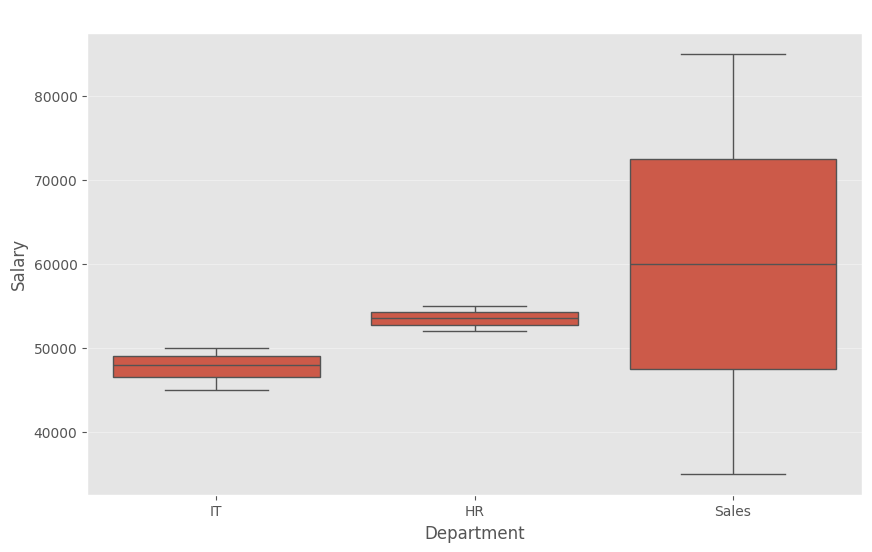

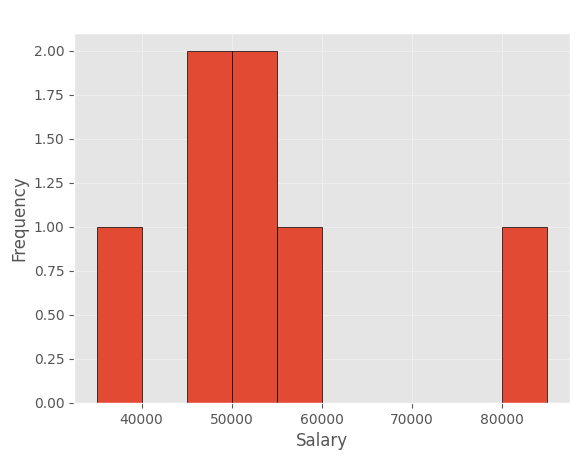

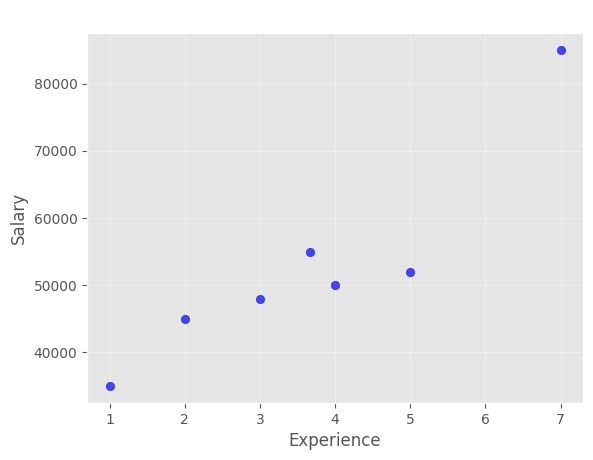

In [22]:
plt.style.use('ggplot')
plt.figure(figsize=(10, 6))
sns.boxplot(x='department', y='salary', data=df)
plt.title('Salary Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Salary')
plt.show()

plt.hist(df['salary'], bins=10, edgecolor='black')
plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

plt.scatter(df['experience'], df['salary'], color='blue', marker='o', alpha=0.7 )
plt.title('Salary vs Experience')
plt.xlabel('Experience')
plt.ylabel('Salary')
plt.show()

In [30]:
department_summary = df.groupby("department").agg(
    emp_count=("employee_id", "count"),
    avg_salary=("salary", "mean"),
    avg_performance_score=("performance_score", "mean")
)

print(department_summary)

            emp_count    avg_salary  avg_performance_score
department                                                
HR                  2  53500.000000               8.500000
IT                  3  47666.666667               6.666667
Sales               2  60000.000000               6.500000
